# Chip Pipeline

1. Crops the orthomosaic into smaller tiles
2. Identifies buildings or candidate structures inside the tiles
3. Discards tiles that do not contain buildings or structures
4. Creates chips from tiles with buildings

In [19]:
!python --version

Python 3.13.16


In [20]:
!pip list

Package                               Version
------------------------------------- -------------------
absl-py                               2.0.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.5
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
anyio                                 4.16.0
anywidget                             0.9.21
apsw                                  3.54.1.0
argon2-cffi                           25.1

In [21]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Packages

In [22]:
import geopandas as gpd
import geemap
import pandas as pd
# import rioxarray as rxr
import rasterio
from rasterio.plot import show
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.features import shapes
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from matplotlib.colors import ListedColormap
import pysal
from affine import Affine
# import contextily as ctx
import xarray as xr
import folium
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import box
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from skimage.segmentation import find_boundaries
from tqdm.auto import tqdm
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
from shapely.geometry import box, shape
from shapely.ops import unary_union
warnings.filterwarnings("ignore")

# 1. Loading data

Unzipping VM8 data from Google Drive.

In [5]:
!unzip -q "/content/drive/MyDrive/remoteclip_data/VM8.zip" -d /content/data

Unzipping data inside VM8.zip into data.

In [6]:
vm8_path= "/content/data/VM8/"
vm8_files = ['terra_dem.rar', 'terra_dom.rar', 'terra_dsm.rar', 'terra_las.rar']
dest = "/content/data/VM8/"

for p in vm8_files:
  path = dest + p.rstrip('.rar')
  os.makedirs(path, exist_ok=True)

Decompressing .rars

In [7]:
!apt-get -qq install unrar

In [8]:
for p in vm8_files:
    rar_path = vm8_path + p
    !unrar x -idq "{rar_path}" "{dest}"

# Variables

In [52]:
DOM_PATH = "/content/data/VM8/terra_dom/dom.tif"
DEM_PATH = "/content/data/VM8/terra_dem/dem.tif"
DSM_PATH = "/content/data/VM8/terra_dsm/dsm.tif"

TILE = 500                # tile size in px
OVERLAP = 0               # px of overlap between neighboring tiles
EDGE = "shift"            # "shift": last row/col moves inward so every tile is exactly TILE x TILE (overlaps its neighbor)
                          # "partial": no overlap, last row/col is smaller (8 px wide here)
MIN_VALID = 0.8           # threshold for valid pixels in tile
F = 10                    # overview factor (~0.5 m/px)
HEIGHT_THR = 2.0          # a structure is anything with nDSM > this (m)
MIN_STRUCT_M2 = 2.0       # smallest structure that counts (m²)
NDSM_RANGE = (-20, 250)   # nDSM values outside this range (m) are treated as nodata

# 1. Tile creation and filtering by nDSM

## V3: Memory efficient

We create a class called TileReader.

In [53]:
class TileReader:
    """Reads one window at a time: RGB, validity mask (alpha) and nDSM. Opens files lazily,
    so it is safe to use after fork (e.g. DataLoader workers)."""

    def __init__(self, dom_path, dsm_path, dem_path, resampling=Resampling.bilinear):
        self.paths, self.resampling, self._h = (dom_path, dsm_path, dem_path), resampling, None

    def _open(self):
        if self._h is None:
            ortho = rasterio.open(self.paths[0])
            srcs = [rasterio.open(p) for p in self.paths[1:]]
            vrts = [WarpedVRT(s, crs=ortho.crs, transform=ortho.transform,
                              width=ortho.width, height=ortho.height,
                              resampling=self.resampling,
                              nodata=s.nodata if s.nodata is not None else np.nan)
                    for s in srcs]
            self._h = (ortho, srcs, vrts)
        return self._h

    def __getstate__(self):                           # handles are not picklable; reopen in the new process
        return {**self.__dict__, "_h": None}

    def close(self):
        if self._h:
            ortho, srcs, vrts = self._h
            for d in [*vrts, *srcs, ortho]:
                d.close()
            self._h = None

    def read(self, col_off, row_off, width, height, image=True):
        ortho, _, (dsm, dem) = self._open()
        w = Window(int(col_off), int(row_off), int(width), int(height))
        valid = ortho.read(4, window=w) > 0
        ndsm = (dsm.read(1, window=w, masked=True).astype("float32")
                - dem.read(1, window=w, masked=True).astype("float32")).filled(np.nan)
        ndsm[~valid | (ndsm < NDSM_RANGE[0]) | (ndsm > NDSM_RANGE[1])] = np.nan
        out = {"valid": valid, "ndsm": ndsm}            # ndsm: float32, NaN = no data
        if image:
            out["image"] = ortho.read([1, 2, 3], window=w)    # (3, h, w) uint8
        return out

reader = TileReader(DOM_PATH, DSM_PATH, DEM_PATH)

In [54]:
step = TILE - OVERLAP

with rasterio.open(DOM_PATH) as src:
    H, W, tf, crs, bounds = src.height, src.width, src.transform, src.crs, src.bounds
    res = src.res[0]
    ov = src.read(out_shape=(src.count, H // F, W // F), resampling=Resampling.average)

valid_ov = ov[3] > 127                                   # footprint from alpha
fy, fx = H / valid_ov.shape[0], W / valid_ov.shape[1]    # full-res px per overview px
yy = (np.arange(valid_ov.shape[0]) + 0.5) * fy           # overview pixel centers, in full-res px
xx = (np.arange(valid_ov.shape[1]) + 0.5) * fx

def starts(total, tile, step):
    if EDGE == "partial":
        return list(range(0, total, step))
    if total <= tile:
        return [0]
    s = list(range(0, total - tile + 1, step))
    if s[-1] + tile < total:
        s.append(total - tile)                           # final tile moved inward to reach the edge
    return s

def ov_slice(row_off, col_off, h, w):
    r0, r1 = np.searchsorted(yy, [row_off, row_off + h])
    c0, c1 = np.searchsorted(xx, [col_off, col_off + w])
    return slice(r0, r1), slice(c0, c1)

records = []
for ri, row_off in enumerate(starts(H, TILE, step)):
    for ci, col_off in enumerate(starts(W, TILE, step)):
        w = Window(col_off, row_off, min(TILE, W - col_off), min(TILE, H - row_off)) # Where the tile is built
        v = valid_ov[ov_slice(row_off, col_off, w.height, w.width)] # Valid pixels
        records.append(dict(ri=ri, ci=ci, col_off=col_off, row_off=row_off,
                            width=int(w.width), height=int(w.height),
                            valid_frac_ov=v.mean() if v.size else 0.0,
                            geometry=box(*window_bounds(w, tf))))

# Tiles are saved in a GeoDataFrame in the grid variable.

grid = gpd.GeoDataFrame(records, crs=crs)
grid["tile_id"] = grid.index
grid["has_data"] = grid.valid_frac_ov > MIN_VALID
print(len(grid), "tiles in the grid:", grid.ci.max() + 1, "cols x", grid.ri.max() + 1, "rows |",
      int(grid.has_data.sum()), "contain data")

# orthomosaic footprint as a polygon (from the overview alpha)
ov_tf = tf * Affine.scale(fx, fy)
footprint = unary_union([shape(g) for g, _ in
                         shapes(valid_ov.astype("uint8"), mask=valid_ov, transform=ov_tf)]
                        ).simplify(fx * res)

# coverage check: every valid pixel must be covered by at least one tile that has data
count = np.zeros(valid_ov.shape, np.int16)
for t in grid[grid.has_data].itertuples():
    count[ov_slice(t.row_off, t.col_off, t.height, t.width)] += 1
print("bounding box not covered by the grid (m²):",
      round(box(*bounds).difference(unary_union(list(grid.geometry))).area, 4))
print("valid pixels not covered:", int((valid_ov & (count == 0)).sum()))

2700 tiles in the grid: 50 cols x 54 rows | 1099 contain data
bounding box not covered by the grid (m²): 0.0
valid pixels not covered: 98175


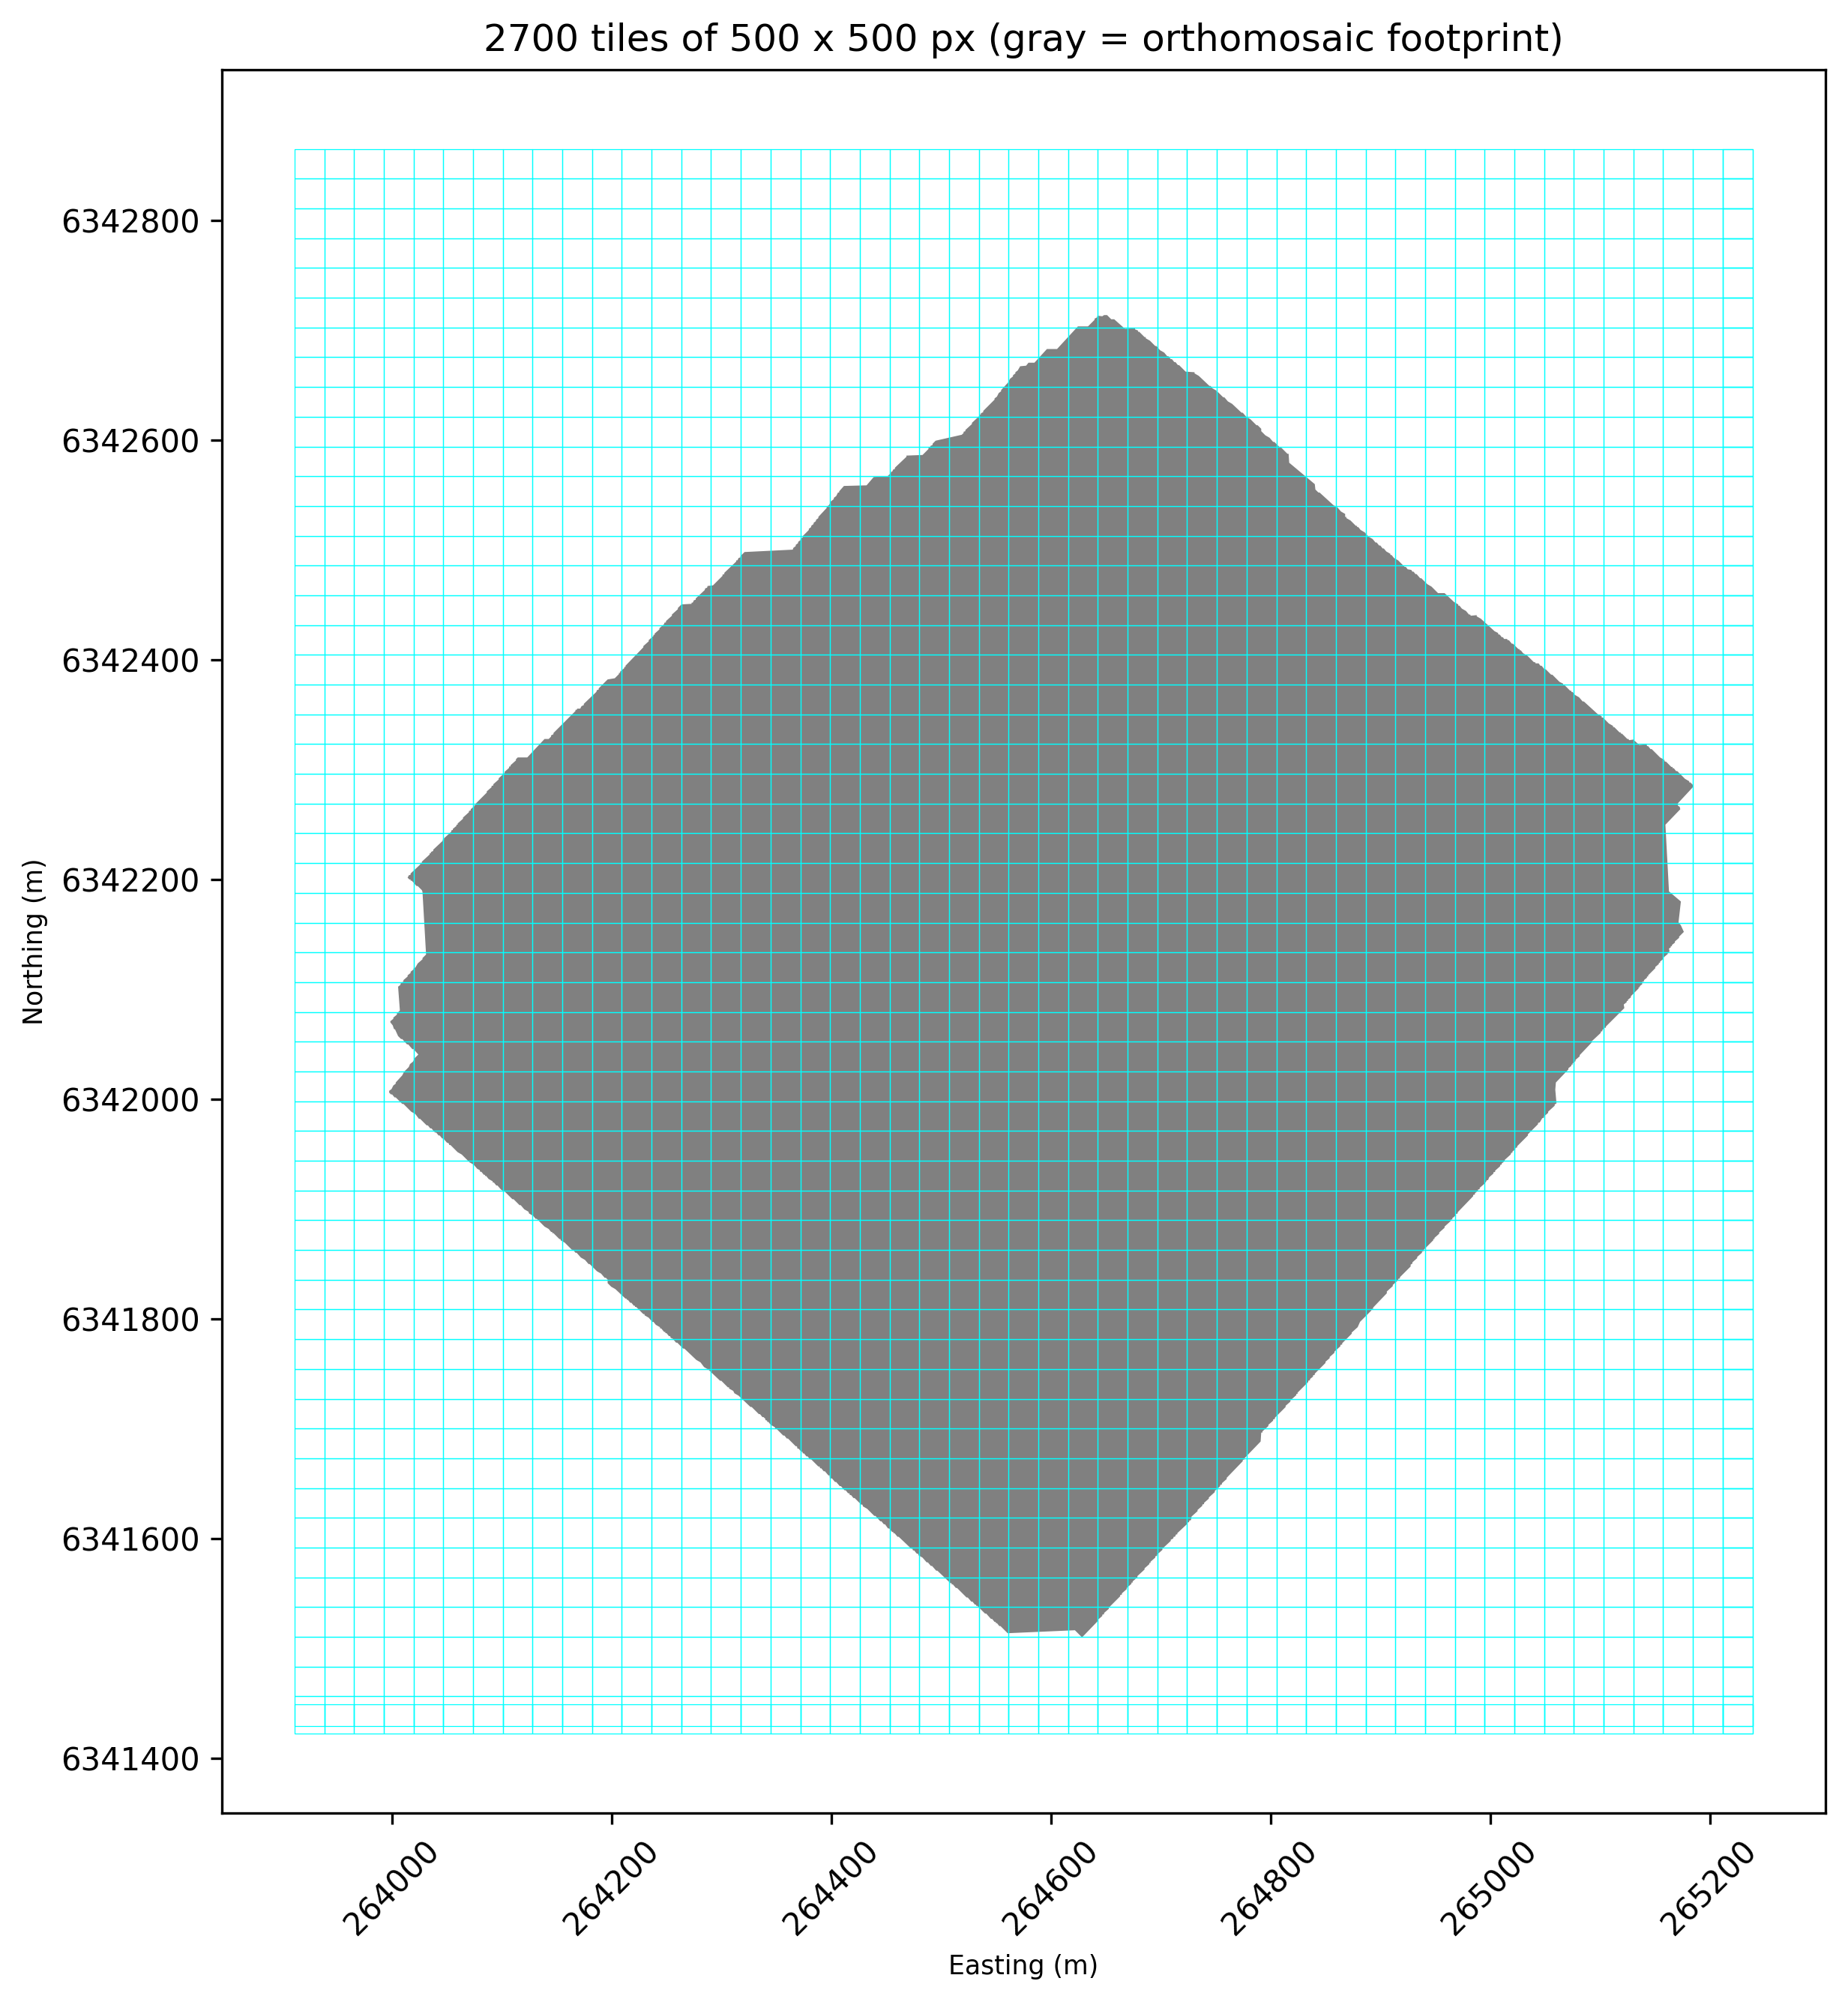

In [55]:
fig, ax = plt.subplots(figsize=(9, 9), dpi=300)
#ax.set_facecolor("#151515")

gpd.GeoSeries([footprint], crs=crs).plot(ax=ax, color="gray")                       # orthomosaic boundary, filled
gpd.GeoSeries([box(*bounds)], crs=crs).boundary.plot(ax=ax, color="white",
                                                     linestyle="--", linewidth=1)   # raster bounding box
grid.boundary.plot(ax=ax, color="cyan", linewidth=0.3)                              # the entire tile grid

ax.set_title(f"{len(grid)} tiles of {TILE} x {TILE} px (gray = orthomosaic footprint)")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [56]:
min_px = int(MIN_STRUCT_M2 / res**2)

def clean_struct(mask):
    mask = ndi.binary_opening(mask, structure=np.ones((3, 3)))     # remove thin noise
    return remove_small_objects(mask, min_size=min_px)

rows = []
todo = grid[grid.has_data]
for t in tqdm(todo.itertuples(), total=len(todo)):
    s = reader.read(t.col_off, t.row_off, t.width, t.height, image=False)
    nd = s["ndsm"]
    fin = np.isfinite(nd)
    m = clean_struct(np.nan_to_num(nd, nan=0.0) > HEIGHT_THR)
    n_valid = int(s["valid"].sum())
    rows.append(dict(tile_id=t.tile_id,
                     valid_frac=n_valid / s["valid"].size,         # exact, full resolution
                     ndsm_cover=fin.sum() / max(n_valid, 1),       # share of valid pixels with an nDSM value
                     struct_px=int(m.sum()),
                     struct_frac=m.sum() / max(n_valid, 1),
                     ndsm_max=float(nd[fin].max()) if fin.any() else np.nan))

stats = pd.DataFrame(rows).set_index("tile_id")
grid = grid.drop(columns=stats.columns, errors="ignore").join(stats)

# group 1: category per tile
has_struct = grid.struct_px.fillna(0) > 0
grid["group"] = np.select([~grid.has_data, has_struct], ["no data", "structures"], default="ground only")

# group 2: clusters of adjacent structure tiles (8-connected on the tile grid)
flag = np.zeros((grid.ri.max() + 1, grid.ci.max() + 1), bool)
flag[grid.ri[has_struct].to_numpy(), grid.ci[has_struct].to_numpy()] = True
lab, n_clusters = ndi.label(flag, structure=np.ones((3, 3)))
grid["cluster"] = lab[grid.ri.to_numpy(), grid.ci.to_numpy()]      # 0 = not a structure tile

print(grid.group.value_counts())
print(n_clusters, "clusters of adjacent structure tiles")
summary = (grid[grid.cluster > 0].groupby("cluster")
           .agg(n_tiles=("tile_id", "size"),
                struct_ha=("struct_px", lambda s: s.sum() * res**2 / 1e4),
                max_height_m=("ndsm_max", "max")).round(2))
print(summary.sort_values("n_tiles", ascending=False).head(15))

  0%|          | 0/1099 [00:00<?, ?it/s]

group
no data        1601
structures     1011
ground only      88
Name: count, dtype: int64
2 clusters of adjacent structure tiles
         n_tiles  struct_ha  max_height_m
cluster                                  
1           1010      19.86         62.43
2              1       0.00          3.03


We can plot the different tile groups.

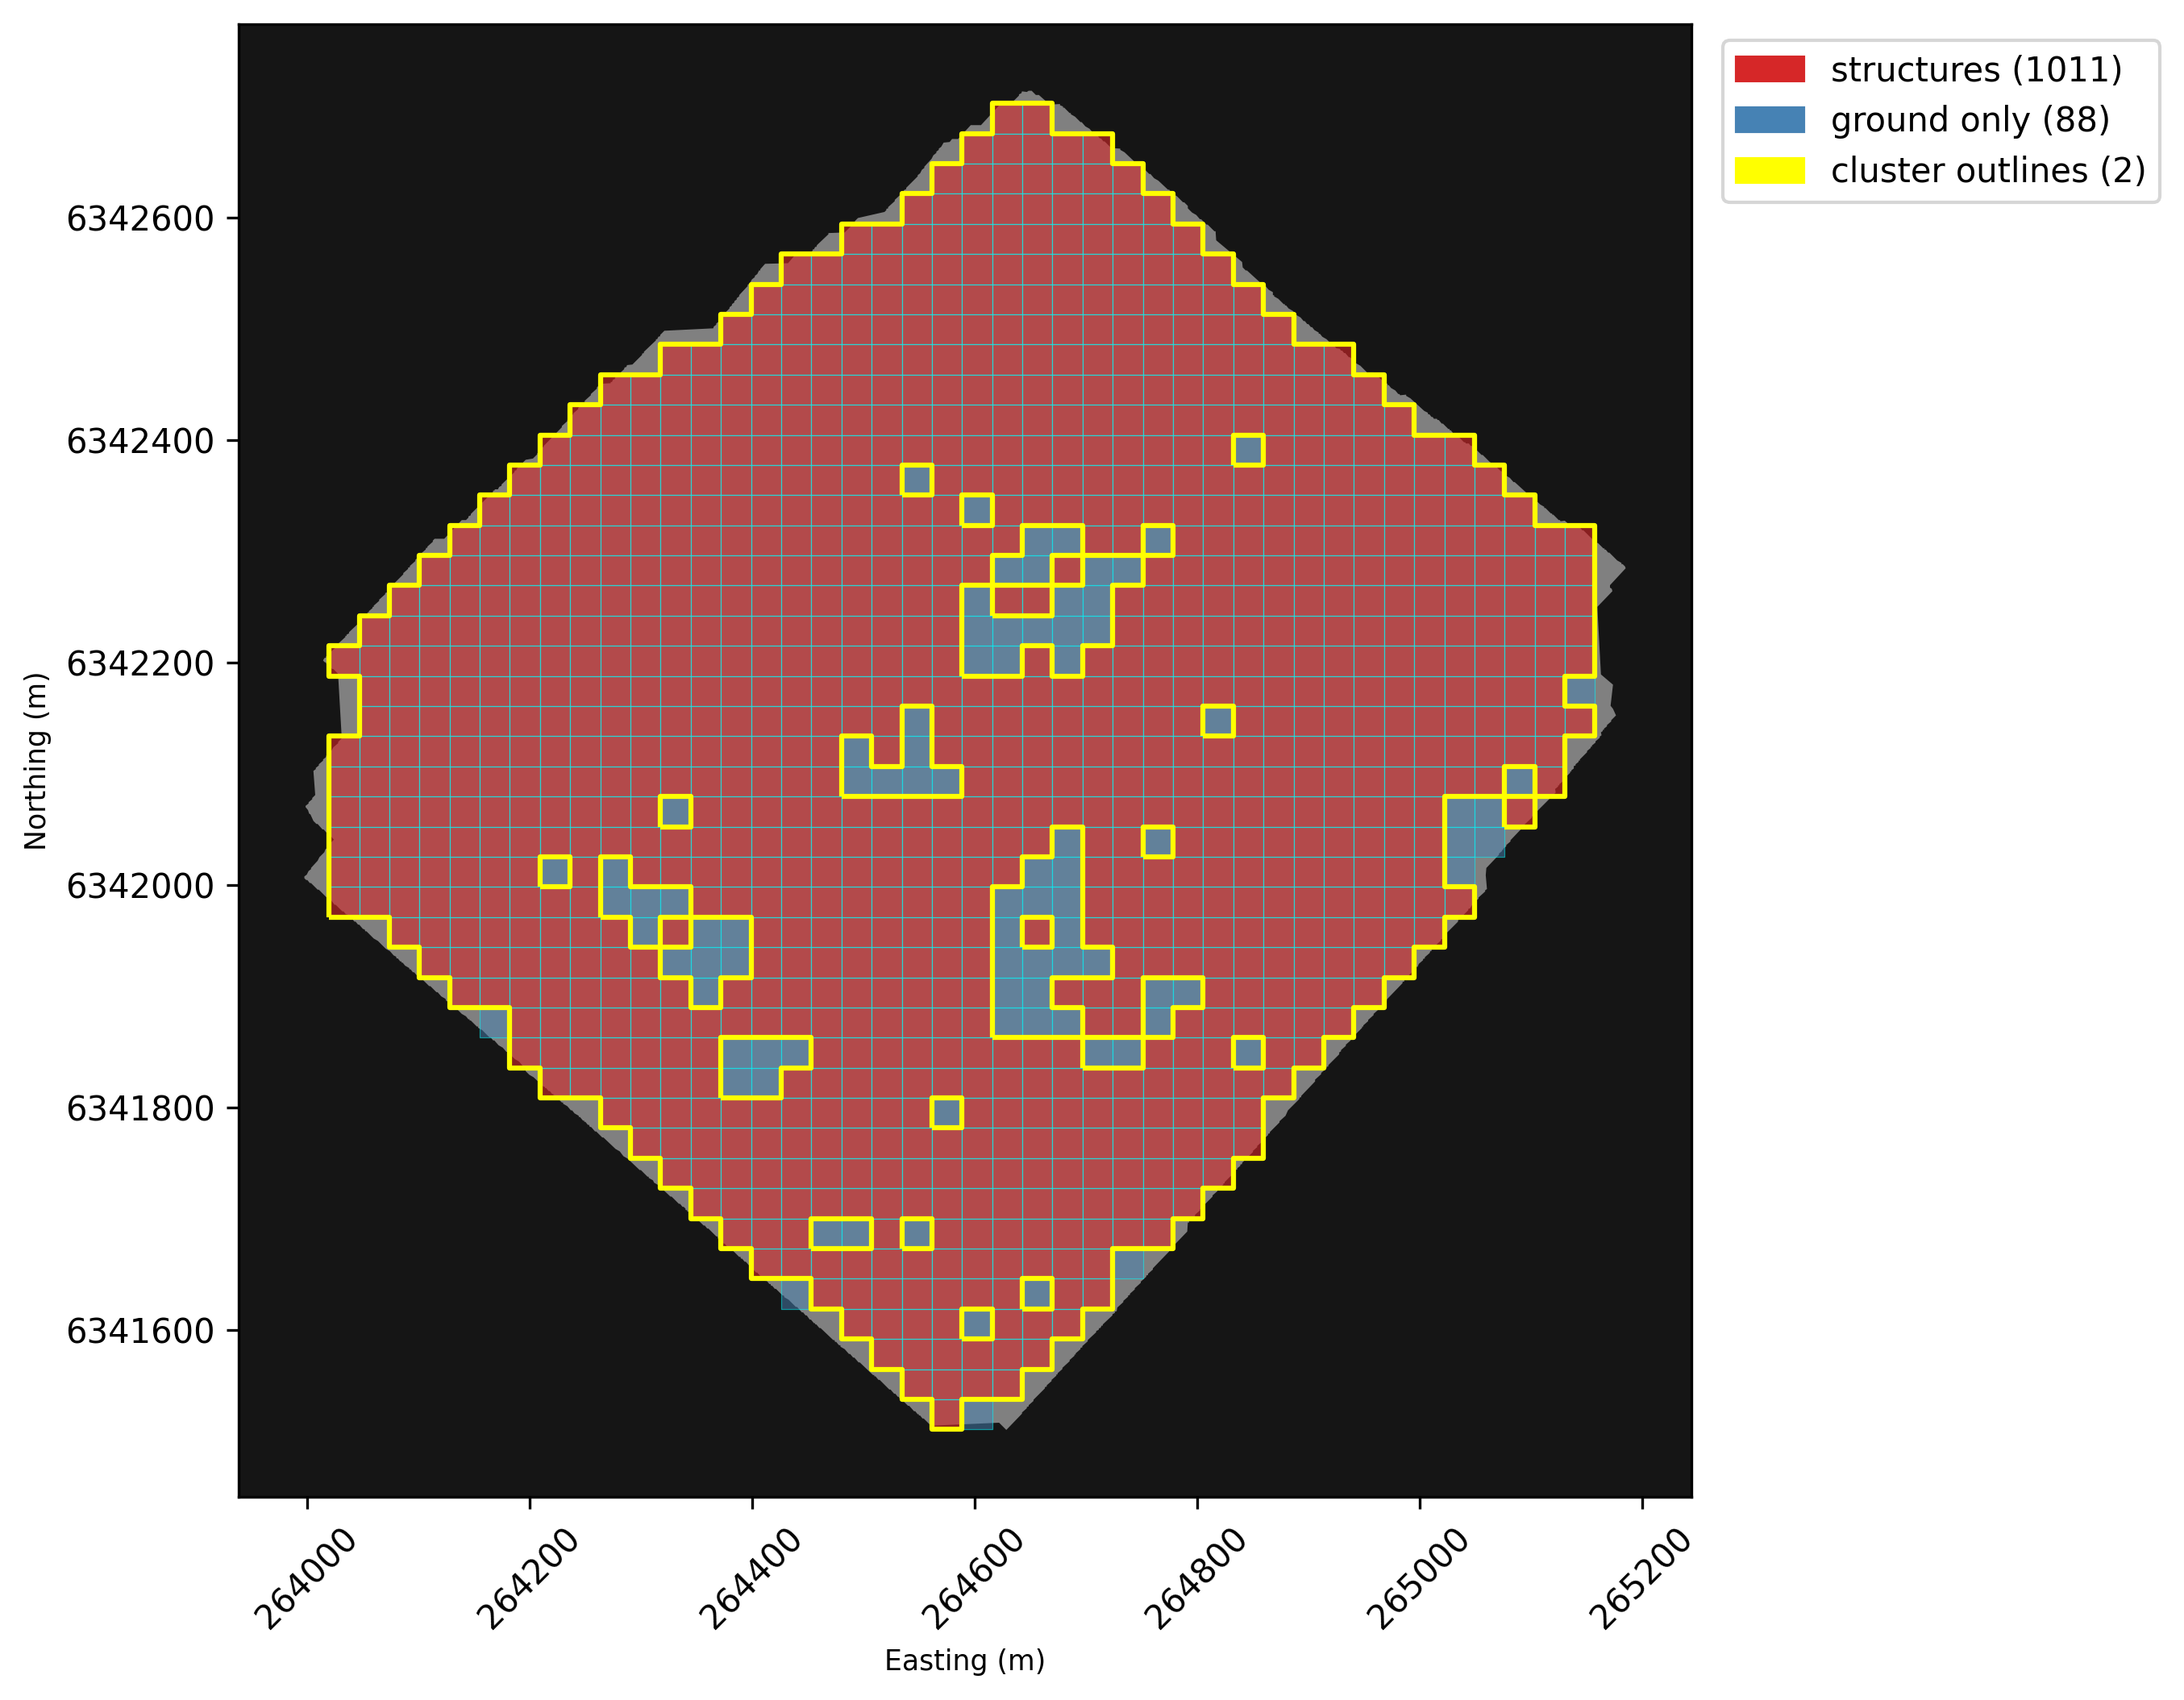

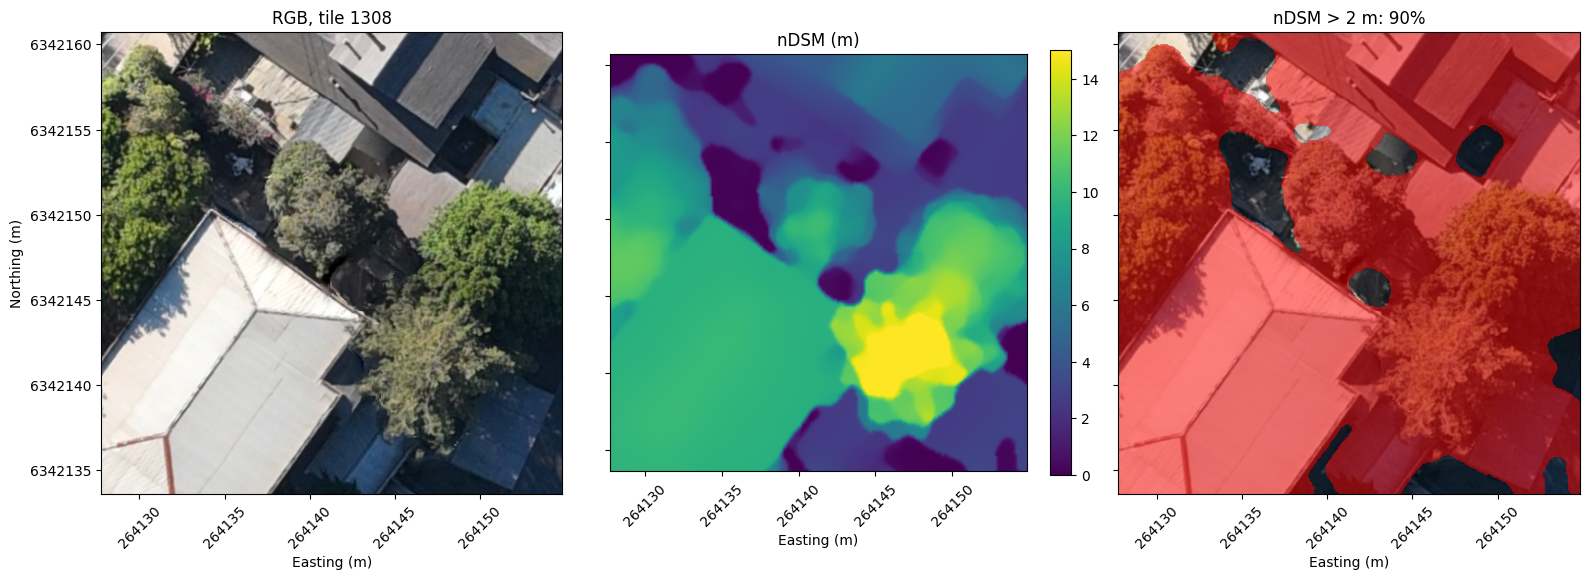

In [57]:
# map of the groups
fig, ax = plt.subplots(figsize=(9, 9), dpi=300)
ax.set_facecolor("#151515")
gpd.GeoSeries([footprint], crs=crs).plot(ax=ax, color="gray")
grid[grid.group == "ground only"].plot(ax=ax, facecolor="steelblue", edgecolor="cyan", alpha=0.5, linewidth=0.3)
grid[grid.group == "structures"].plot(ax=ax, facecolor="tab:red", edgecolor="cyan", alpha=0.6, linewidth=0.3)
if n_clusters:
    grid[grid.cluster > 0].dissolve("cluster").boundary.plot(ax=ax, color="yellow", linewidth=1.5)
ax.legend(handles=[Patch(color="tab:red", label=f"structures ({(grid.group == 'structures').sum()})"),
                   Patch(color="steelblue", label=f"ground only ({(grid.group == 'ground only').sum()})"),
                   Patch(color="yellow", label=f"cluster outlines ({n_clusters})")],
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


# one tile: RGB | nDSM | structures above the threshold
def show_tile(tile_id):
    t = grid.loc[tile_id]
    s = reader.read(t.col_off, t.row_off, t.width, t.height)
    m = clean_struct(np.nan_to_num(s["ndsm"], nan=0.0) > HEIGHT_THR)
    l, b, r, tp = t.geometry.bounds
    ext = (l, r, b, tp)
    rgb = s["image"].transpose(1, 2, 0)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
    axes[0].imshow(rgb, extent=ext); axes[0].set_title(f"RGB, tile {tile_id}")
    im = axes[1].imshow(s["ndsm"], cmap="viridis", vmin=0, vmax=15, extent=ext)
    axes[1].set_title("nDSM (m)"); plt.colorbar(im, ax=axes[1], fraction=0.046)
    axes[2].imshow(rgb, extent=ext)
    axes[2].imshow(np.ma.masked_where(~m, m), cmap="autumn", alpha=0.5, extent=ext)
    axes[2].set_title(f"nDSM > {HEIGHT_THR:g} m: {m.mean():.0%}")
    for ax in axes:
        ax.set_xlabel("Easting (m)")
        ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=45)
    axes[0].set_ylabel("Northing (m)")
    plt.tight_layout(); plt.show()

show_tile(grid[grid.group == "structures"].struct_frac.idxmax())    # the tile with the largest structure share

In [58]:
# lazy dataset of the structure tiles (nothing is cached; each item is read on demand)
class TileDataset:
    def __init__(self, table, reader):
        self.t, self.reader = table.reset_index(drop=True), reader

    def __len__(self):
        return len(self.t)

    def __getitem__(self, i):
        r = self.t.iloc[i]
        s = self.reader.read(r.col_off, r.row_off, r.width, r.height)   # image, valid, ndsm
        s["mask"] = clean_struct(np.nan_to_num(s["ndsm"], nan=0.0) > HEIGHT_THR)
        s["tile_id"], s["cluster"] = int(r.tile_id), int(r.cluster)
        return s

ds = TileDataset(grid[grid.group == "structures"], reader)
sample = ds[0]          # image (3,500,500) uint8 | valid (500,500) bool | ndsm float32 | mask bool

Notes on how the tiles are saved

1011
<class 'dict'>
dict_keys(['valid', 'ndsm', 'image', 'mask', 'tile_id', 'cluster'])


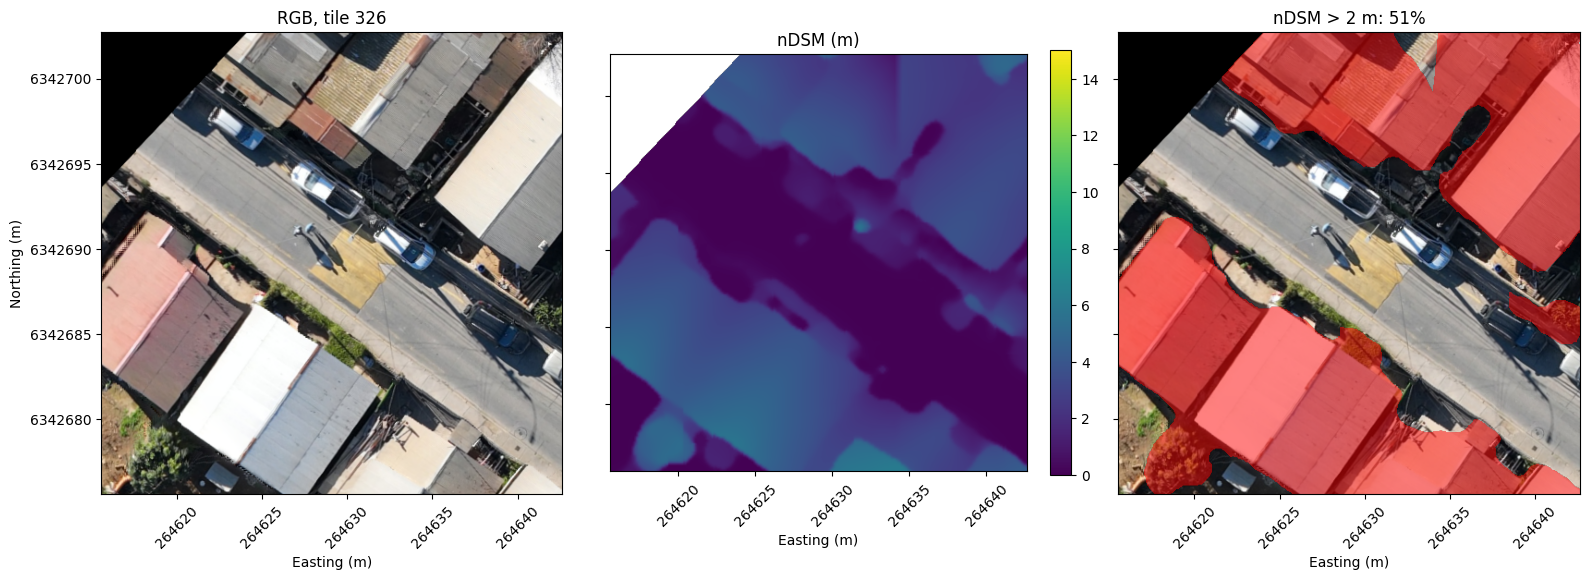

In [59]:
# All of the tiles are saved in the 'ds' variable as a TileDataSet object
# You can use len() on TileDataSet objects
print(len(ds))
# They are iterable, you can use ds[0] to revise each tile
print(type(ds[0]))
# Each tile is saved in the class as a dictionary with keys.
print(ds[0].keys())

# We can print the image of a single tile by using the show_tile function
show_tile(sample['tile_id'])

In [60]:
from pathlib import Path
OUT = Path("/content/drive/MyDrive/roof_chips")
(OUT / "tiles").mkdir(parents=True, exist_ok=True)

# ownership: each object is kept only by the tile cell that contains its centroid (no duplicates in overlap strips)
step = TILE - OVERLAP
grid["own_r0"] = grid.ri * step
grid["own_r1"] = np.where(grid.ri == grid.ri.max(), H, (grid.ri + 1) * step)
grid["own_c0"] = grid.ci * step
grid["own_c1"] = np.where(grid.ci == grid.ci.max(), W, (grid.ci + 1) * step)

grid.to_parquet(OUT / "grid.parquet")
# in a new session, after rerunning the setup cell with TileReader, clean_struct, etc.:
# grid = gpd.read_parquet(OUT / "grid.parquet")

# Creating chips

In [61]:
import csv, json, time, torch
from PIL import Image
from skimage.morphology import h_maxima
from skimage.segmentation import watershed

In [62]:
# ---- parameters ----
CKPT = "/content/drive/MyDrive/sam/sam_vit_b_01ec64.pth"
HALO = 64               # px of context around each tile cell
CHIP = 224
MARGIN = 0.25           # context around the object, as a fraction of its size on each side
MIN_SIDE = 96           # smallest source window for a chip (px)
MIN_AREA = 5
BG_FADE = 0.0           # 0 = keep surroundings; 1 = paint everything outside the object gray
SPLIT, H_M = True, 0.7  # split touching objects (neck depth in m; larger = fewer splits)
PAD_PX, DILATE_PX, MIN_INSIDE = 8, 12, 0.6
TIME_BUDGET_MIN = None  # e.g. 90 to stop cleanly before a Colab limit

device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "Switch the Colab runtime to a GPU"
predictor = SamPredictor(sam_model_registry["vit_b"](checkpoint=CKPT).to(device))

FIELDS = ["chip_id", "filepath", "tile_id", "ri", "ci", "cluster", "center_e", "center_n",
          "col_px", "row_px", "area_m2", "height_mean", "height_max", "sam_score", "source", "chip_gsd_cm"]
MIN_CHIP_VALID = 1.0                         # share of chip pixels that must be real data (alpha > 0); 0.99 is more lenient
MARGIN_TRIES = [MARGIN, MARGIN / 2, 0.0]     # try less context before dropping an object near the edge
skipped = {"no_data": 0}
src_rgba = rasterio.open(DOM_PATH)           # chips are cut straight from the orthomosaic

FIELDS = FIELDS + ["chip_valid_frac", "chip_ok"]    # run the repair in step 3 first if chips.csv already exists


In [63]:
def seed_regions(struct):
    comp, n = ndi.label(struct, structure=np.ones((3, 3)))
    dist = ndi.distance_transform_edt(struct)
    markers = np.zeros(struct.shape, np.int32)
    if SPLIT:
        markers = ndi.label(h_maxima(dist, H_M / res))[0].astype(np.int32)
        markers[~struct] = 0
    k = int(markers.max())
    missing = np.setdiff1d(np.arange(1, n + 1), np.unique(comp[markers > 0])).tolist()
    if missing:
        for r, c in ndi.maximum_position(dist, comp, missing):     # components with no seed get one
            k += 1
            markers[r, c] = k
    return watershed(-dist, markers, mask=struct), dist


def find_objects(win, chunk=32, iou_thr=0.6):
    """win = (col_off, row_off, width, height). Returns image (h,w,3), ndsm (h,w), list of objects."""
    s = reader.read(*win)
    img = np.ascontiguousarray(s["image"].transpose(1, 2, 0))
    nd = s["ndsm"]
    h, w = nd.shape
    struct = clean_struct(np.nan_to_num(nd, nan=0.0) > HEIGHT_THR)
    if not struct.any():
        return img, nd, []

    regions, dist = seed_regions(struct)
    ids = np.unique(regions[regions > 0])
    objs = ndi.find_objects(regions)
    pos = ndi.maximum_position(dist, regions, ids.tolist())
    boxes, pts = [], []
    for k, (r, c) in zip(ids, pos):
        sl = objs[k - 1]
        boxes.append([max(sl[1].start - PAD_PX, 0), max(sl[0].start - PAD_PX, 0),
                      min(sl[1].stop + PAD_PX, w), min(sl[0].stop + PAD_PX, h)])
        pts.append([c, r])                                          # (x, y)

    predictor.set_image(img)                                        # embedding, once per window
    b_t = predictor.transform.apply_boxes_torch(torch.tensor(boxes, dtype=torch.float32, device=device), (h, w))
    p_t = predictor.transform.apply_coords_torch(
        torch.tensor(pts, dtype=torch.float32, device=device)[:, None, :], (h, w))
    lab = torch.ones((len(pts), 1), dtype=torch.int, device=device)
    masks, scores = [], []
    for a in range(0, len(ids), chunk):
        m, sc, _ = predictor.predict_torch(p_t[a:a + chunk], lab[a:a + chunk],
                                           boxes=b_t[a:a + chunk], multimask_output=False)
        masks.append(m[:, 0].cpu().numpy()); scores.append(sc[:, 0].cpu().numpy())
    masks, scores = np.concatenate(masks), np.concatenate(scores)

    near = ndi.distance_transform_edt(~struct) <= DILATE_PX         # SAM may not leak far from the >2 m mask
    final, src = [], []
    for k, m in zip(ids, masks):
        m = m & near
        n_m = int(m.sum())
        if n_m < min_px or (m & struct).sum() / n_m < MIN_INSIDE:
            final.append(regions == k); src.append("ndsm")
        else:
            final.append(m); src.append("sam")

    small = torch.from_numpy(np.stack([m[::4, ::4] for m in final])).float().flatten(1).to(device)
    inter, area = small @ small.T, small.sum(1)
    iou = (inter / (area[:, None] + area[None] - inter).clamp(min=1)).cpu().numpy()
    keep = []                                                       # drop near-duplicate masks (best score wins)
    for k in np.argsort(-scores):
        if all(iou[k, j] <= iou_thr for j in keep):
            keep.append(int(k))
    keep.sort()
    return img, nd, [dict(mask=final[k], score=float(scores[k]), source=src[k]) for k in keep]



def cut_chip(gx, gy, obj_px):
    """Chip centered on (gx, gy) in full-res px. Returns (chip, valid_frac, (x0, y0, side)) or None."""
    for mg in MARGIN_TRIES:
        side = int(min(max(np.ceil(obj_px * (1 + 2 * mg)), MIN_SIDE), H, W))
        x0 = int(np.clip(round(gx - side / 2), 0, W - side))       # shift to stay inside the raster, never pad
        y0 = int(np.clip(round(gy - side / 2), 0, H - side))
        d = src_rgba.read(window=Window(x0, y0, side, side))       # (4, side, side)
        vfrac = float((d[3] > 0).mean())
        if vfrac >= MIN_CHIP_VALID:
            rgb = Image.fromarray(np.ascontiguousarray(d[:3].transpose(1, 2, 0)))
            return rgb.resize((CHIP, CHIP), Image.LANCZOS), vfrac, (x0, y0, side)
    return None


def process_tile(t):
    c0 = max(int(t.own_c0) - HALO, 0); c1 = min(int(t.own_c1) + HALO, W)
    r0 = max(int(t.own_r0) - HALO, 0); r1 = min(int(t.own_r1) + HALO, H)
    img, nd, objs = find_objects((c0, r0, c1 - c0, r1 - r0))
    rows, k = [], 0
    for o in objs:
        m = o["mask"]
        ys, xs = np.nonzero(m)
        if ys.size < min_px:
            continue
        gy, gx = r0 + ys.mean(), c0 + xs.mean()
        if not (t.own_r0 <= gy < t.own_r1 and t.own_c0 <= gx < t.own_c1):
            continue
        k += 1                                                      # ids count every owned object, so they stay stable
        cid = f"t{int(t.tile_id):04d}_o{k:03d}"
        out = cut_chip(gx, gy, max(np.ptp(ys), np.ptp(xs)) + 1)
        if out is None:
            skipped["no_data"] += 1
            continue
        chip, vfrac, (x0, y0, side) = out
        if BG_FADE > 0:
            box_ = (x0 - c0, y0 - r0, x0 - c0 + side, y0 - r0 + side)   # window coordinates
            mm = np.asarray(Image.fromarray(m.astype(np.uint8) * 255).crop(box_)
                            .resize((CHIP, CHIP), Image.NEAREST)) > 0
            arr = np.asarray(chip).astype(np.float32)
            chip = Image.fromarray(np.where(mm[..., None], arr, arr * (1 - BG_FADE) + 128 * BG_FADE).astype(np.uint8))
        chip.save(OUT / "chips" / f"{cid}.png")
        e, n = tf * (gx + 0.5, gy + 0.5)
        hv = nd[m]; hv = hv[np.isfinite(hv)]
        rows.append(dict(chip_id=cid, filepath=f"chips/{cid}.png", tile_id=int(t.tile_id), ri=int(t.ri),
                         ci=int(t.ci), cluster=int(t.cluster), center_e=round(e, 2), center_n=round(n, 2),
                         col_px=round(gx, 1), row_px=round(gy, 1), area_m2=round(ys.size * res**2, 2),
                         height_mean=round(float(hv.mean()), 2) if hv.size else np.nan,
                         height_max=round(float(hv.max()), 2) if hv.size else np.nan,
                         sam_score=round(o["score"], 4), source=o["source"],
                         chip_gsd_cm=round(res * 100 * side / CHIP, 2),
                         chip_valid_frac=round(vfrac, 4), chip_ok=True))
    return rows

In [64]:
# ---- run (resumable: skips tiles already done) ----
done_f, man_f = OUT / "done_tiles.txt", OUT / "chips.csv"
done = set(map(int, done_f.read_text().split())) if done_f.exists() else set()
todo = grid[(grid.group == "structures") & ~grid.tile_id.isin(done)]
print(len(todo), "tiles to process,", len(done), "already done")

t_start = time.time()
for t in tqdm(todo.itertuples(), total=len(todo)):
    rows = process_tile(t)
    if rows:
        new = not man_f.exists()
        with open(man_f, "a", newline="") as fh:
            wr = csv.DictWriter(fh, fieldnames=FIELDS)
            if new:
                wr.writeheader()
            wr.writerows(rows)
    with open(done_f, "a") as fh:                                   # marked only after its chips are written
        fh.write(f"{int(t.tile_id)}\n")
    if TIME_BUDGET_MIN and time.time() - t_start > TIME_BUDGET_MIN * 60:
        print("time budget reached, rerun this cell to continue"); break

0 tiles to process, 1022 already done


0it [00:00, ?it/s]

## Overview

4702 chips from 999 tiles
source
sam     3997
ndsm     705
Name: count, dtype: int64
       area_m2  height_mean  chip_gsd_cm
count  4702.00      4702.00      4702.00
mean     39.84         4.22         5.80
std      53.18         3.29         4.01
min       2.00         1.69         2.32
25%       6.09         2.44         2.40
50%      17.26         3.19         4.40
75%      58.40         4.82         8.06
max     735.65        58.57        22.79


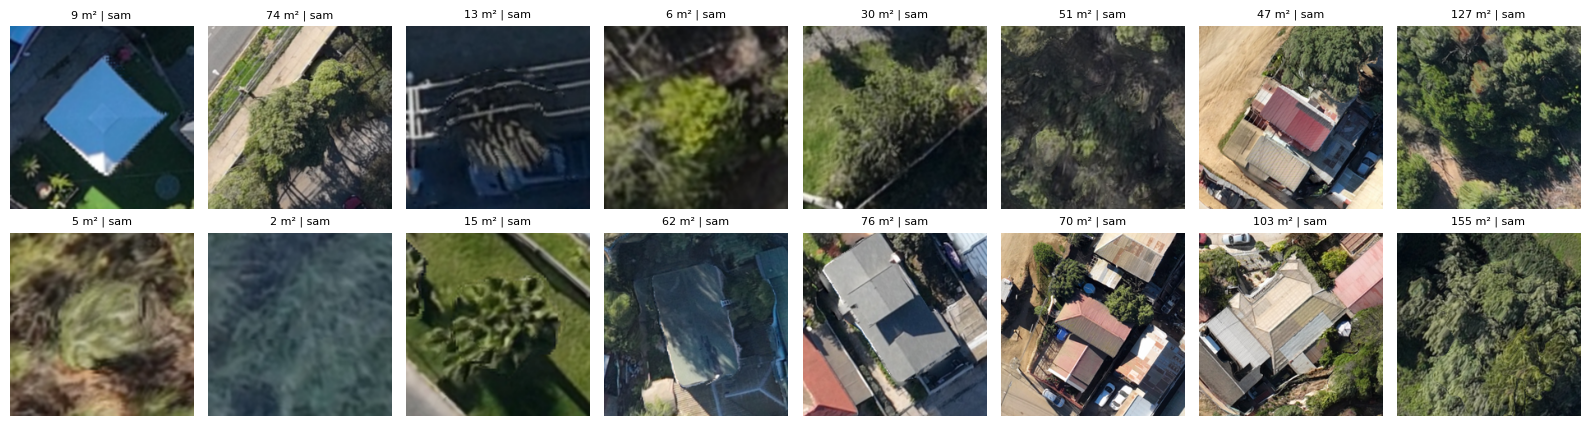

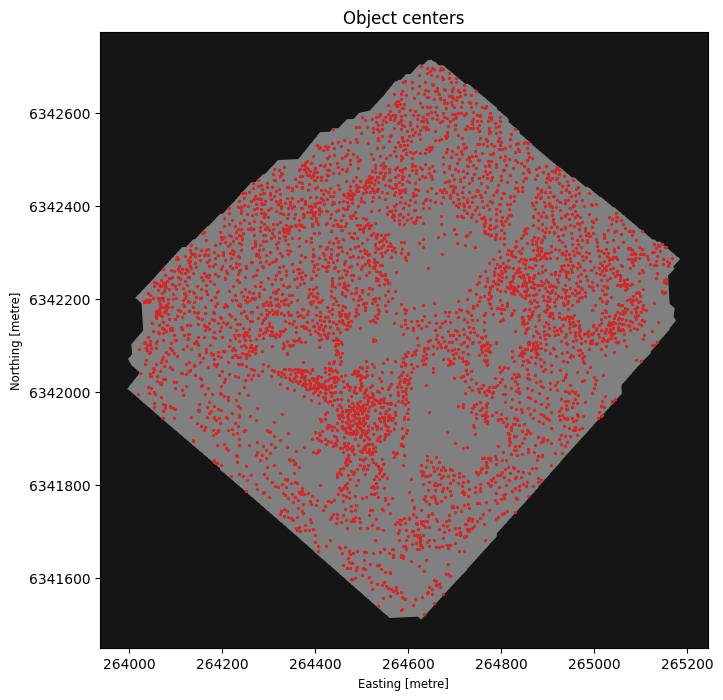

In [65]:
chips = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last")
print(len(chips), "chips from", chips.tile_id.nunique(), "tiles")
print(chips.source.value_counts())
print(chips[["area_m2", "height_mean", "chip_gsd_cm"]].describe().round(2))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, (_, r) in zip(axes.ravel(), chips.sample(16, random_state=0).iterrows()):
    ax.imshow(Image.open(OUT / r.filepath)); ax.axis("off")
    ax.set_title(f"{r.area_m2:.0f} m² | {r.source}", fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 8)); ax.set_facecolor("#151515")
gpd.GeoSeries([footprint], crs=crs).plot(ax=ax, color="gray")
ax.scatter(chips.center_e, chips.center_n, s=2, c="tab:red")
ax.ticklabel_format(useOffset=False, style="plain"); ax.set_title("Object centers"); plt.show()

## Debugging

Fixing chips that come back with too much empty data. First, determining the issue.

In [66]:
from shapely.geometry import Point

chips = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last")
chips["black_frac"] = [float((np.asarray(Image.open(OUT / fp)).sum(-1) == 0).mean())
                       for fp in tqdm(chips.filepath)]
chips["dist_edge_m"] = [footprint.boundary.distance(Point(e, n))
                        for e, n in zip(chips.center_e, chips.center_n)]
chips["half_diag_m"] = chips.chip_gsd_cm / 100 * CHIP / 2 * 1.42      # chip center-to-corner distance

bad = chips[chips.black_frac > 0.02]
print(len(bad), "of", len(chips), "chips have more than 2% black pixels")
print("near the footprint edge (cause 1):", int((bad.dist_edge_m < bad.half_diag_m).sum()))
print("elsewhere, window padding (cause 2):", int((bad.dist_edge_m >= bad.half_diag_m).sum()))

  0%|          | 0/4702 [00:00<?, ?it/s]

67 of 4702 chips have more than 2% black pixels
near the footprint edge (cause 1): 67
elsewhere, window padding (cause 2): 0


Repairing chips that are already done

In [67]:
import shutil

def repair_chips(black_tol=0.001):
    m = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last").reset_index(drop=True)
    shutil.copy(man_f, OUT / "chips_before_repair.csv")
    vf, gsd, ok, fixed = [], [], [], 0
    for r in tqdm(m.itertuples(), total=len(m)):
        bf = float((np.asarray(Image.open(OUT / r.filepath)).sum(-1) == 0).mean())
        if bf <= black_tol:                                           # chip is fine, leave it
            vf.append(round(1 - bf, 4)); gsd.append(r.chip_gsd_cm); ok.append(True); continue
        side_old = r.chip_gsd_cm / (res * 100) * CHIP                 # original source window size
        out = cut_chip(r.col_px, r.row_px, side_old / (1 + 2 * MARGIN))
        if out is None:                                               # cannot reach MIN_CHIP_VALID
            vf.append(round(1 - bf, 4)); gsd.append(r.chip_gsd_cm); ok.append(False); continue
        chip, v, (x0, y0, side) = out
        chip.save(OUT / r.filepath)
        vf.append(round(v, 4)); gsd.append(round(res * 100 * side / CHIP, 2)); ok.append(True); fixed += 1
    m["chip_valid_frac"], m["chip_gsd_cm"], m["chip_ok"] = vf, gsd, ok
    m.to_csv(man_f, index=False)
    print(f"{len(m)} chips | re-cut: {fixed} | cannot be fixed (chip_ok = False): {int((~m.chip_ok).sum())}")
    return m

manifest_fixed = repair_chips()

  0%|          | 0/4702 [00:00<?, ?it/s]

4702 chips | re-cut: 11 | cannot be fixed (chip_ok = False): 70


In [68]:
manifest = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last").reset_index(drop=True)
if "chip_ok" in manifest:
    manifest = manifest[manifest.chip_ok].reset_index(drop=True)      # drop chips that still contain no-data

Checking old vs new chips

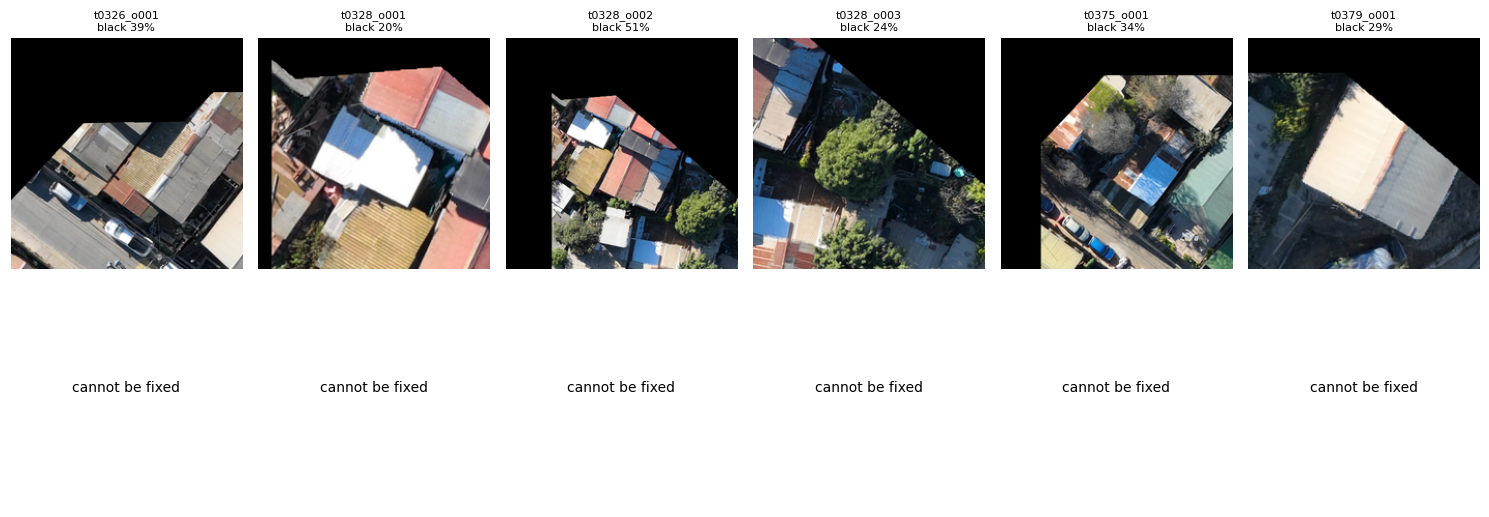

In [69]:
bad = chips[chips.black_frac > 0.02].head(6)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for j, r in enumerate(bad.itertuples()):
    side_old = r.chip_gsd_cm / (res * 100) * CHIP
    out = cut_chip(r.col_px, r.row_px, side_old / (1 + 2 * MARGIN))
    axes[0, j].imshow(Image.open(OUT / r.filepath))
    axes[0, j].set_title(f"{r.chip_id}\nblack {r.black_frac:.0%}", fontsize=8)
    if out:
        axes[1, j].imshow(out[0]); axes[1, j].set_title(f"re-cut, valid {out[1]:.0%}", fontsize=8)
    else:
        axes[1, j].text(0.5, 0.5, "cannot be fixed", ha="center")
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## Primitive labeler/viewer

In [72]:
import ipywidgets as widgets
from IPython.display import display

LABELS = ["light metal sheet", "oxidized metal sheet", "precarious/mixed", "vegetation", "other"]
manifest = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last").reset_index(drop=True)
LABEL_FILE = OUT / "labels.csv"
labels = {}
if LABEL_FILE.exists():
    _l = pd.read_csv(LABEL_FILE)
    labels = dict(zip(_l.chip_id, _l.label))

def save_labels():
    tmp = LABEL_FILE.with_suffix(".tmp")
    pd.DataFrame({"chip_id": list(labels), "label": list(labels.values())}).to_csv(tmp, index=False)
    tmp.replace(LABEL_FILE)

state = {"order": np.arange(len(manifest)), "pos": 0}

img_w = widgets.Image(format="png", width=448, height=448)
info = widgets.HTML()
counts = widgets.HTML()
order_dd = widgets.Dropdown(options=["as extracted", "random", "unlabeled only"], description="Order:")
colors = ["#7a7a7a", "#e0a070", "#d6b656", "#347039", "#30365c"]
label_btns = [widgets.Button(description=f"{i + 1}  {l}", layout=widgets.Layout(width="190px", height="40px"))
              for i, l in enumerate(LABELS)]
for b, c in zip(label_btns, colors):
    b.style.button_color = c
b_prev = widgets.Button(description="◀ Prev")
b_next = widgets.Button(description="Next ▶ (skip)")
b_clear = widgets.Button(description="Clear label")

def draw():
    n, pos = len(state["order"]), state["pos"]
    if n == 0:
        info.value = "Nothing to show."; return
    r = manifest.iloc[state["order"][pos]]
    img_w.value = (OUT / r.filepath).read_bytes()
    cur = labels.get(r.chip_id, "unlabeled")
    info.value = (f"{r.chip_id}   {pos + 1}/{n}area {r.area_m2:.0f} m²  |  "
                  f"height {r.height_mean:.1f} m (max {r.height_max:.1f})  |  source {r.source}"
                  f"current label: {cur}")
    cnt = pd.Series(labels).value_counts()
    counts.value = f"labeled {len(labels)}/{len(manifest)}  |  " + \
                   "  |  ".join(f"{l}: {cnt.get(l, 0)}" for l in LABELS)
    b_prev.disabled, b_next.disabled = pos == 0, pos == n - 1

def go(pos):
    state["pos"] = int(max(0, min(len(state["order"]) - 1, pos))); draw()

def assign(label):
    labels[manifest.iloc[state["order"][state["pos"]]].chip_id] = label
    save_labels(); go(state["pos"] + 1)

def clear(_):
    labels.pop(manifest.iloc[state["order"][state["pos"]]].chip_id, None); save_labels(); draw()

def set_order(change):
    mode, idx = change["new"], np.arange(len(manifest))
    if mode == "random":
        idx = np.random.default_rng(0).permutation(idx)
    elif mode == "unlabeled only":
        idx = idx[~manifest.chip_id.isin(labels).to_numpy()]
    state["order"], state["pos"] = idx, 0; draw()

for b, l in zip(label_btns, LABELS):
    b.on_click(lambda _, l=l: assign(l))
b_prev.on_click(lambda _: go(state["pos"] - 1))
b_next.on_click(lambda _: go(state["pos"] + 1))
b_clear.on_click(clear)
order_dd.observe(set_order, names="value")

display(widgets.VBox([order_dd, counts, widgets.HBox([img_w, widgets.VBox(label_btns)]),
                      info, widgets.HBox([b_prev, b_next, b_clear])]))
draw()

## Secondary viewer for exclusively visual inspection

In [71]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

GRID = 3
PER_PAGE = GRID * GRID
LABELS = ["light metal sheet", "oxidized metal sheet", "precarious/mixed", "vegetation", "other"]
LABEL_FILE = OUT / "labels.csv"
FRAME = {"light metal sheet": "#9e9e9e", "oxidized metal sheet": "#e07b39", "precarious/mixed": "#d4b106",
         "vegetation": "#2e9e4f", "other": "#5b6cff"}
FILTERS = ["all chips", "usable only (chip_ok)", "unfixed only (chip_ok = False)",
           "SAM rejected (source = ndsm)", "unlabeled"] + LABELS
ORDERS = ["as extracted", "random", "SAM score (low first)", "area (large first)"]


def load_chips():
    df = pd.read_csv(man_f).drop_duplicates("chip_id", keep="last").reset_index(drop=True)
    if "chip_ok" not in df:                                   # manifest from before the repair step
        df["chip_ok"] = True
    df["chip_ok"] = df.chip_ok.astype(bool)
    return df

def load_labels():
    if LABEL_FILE.exists():
        l = pd.read_csv(LABEL_FILE)
        return dict(zip(l.chip_id, l.label))
    return {}

state = {"df": load_chips(), "idx": np.array([], int), "page": 0}

# ---- widgets ----
mode_dd = widgets.Dropdown(options=FILTERS, value="all chips", description="Show:",
                           layout=widgets.Layout(width="340px"))
order_dd = widgets.Dropdown(options=ORDERS, description="Order:", layout=widgets.Layout(width="290px"))
b_reload = widgets.Button(description="Reload manifest")
b_first, b_prev = widgets.Button(description="⏮"), widgets.Button(description="◀ Prev")
b_next, b_last = widgets.Button(description="Next ▶"), widgets.Button(description="⏭")
page_box = widgets.BoundedIntText(value=1, min=1, max=1, description="Page:", layout=widgets.Layout(width="140px"))
jump_txt = widgets.Text(placeholder="chip id", layout=widgets.Layout(width="170px"))
jump_btn = widgets.Button(description="Go to chip")
info, out = widgets.HTML(), widgets.Output()


def build_index():
    df, lab = state["df"], load_labels()
    mode, order = mode_dd.value, order_dd.value
    if mode == "usable only (chip_ok)":
        mask = df.chip_ok
    elif mode.startswith("unfixed"):
        mask = ~df.chip_ok
    elif mode.startswith("SAM rejected"):
        mask = df.source.eq("ndsm")
    elif mode == "unlabeled":
        mask = ~df.chip_id.isin(lab)
    elif mode in LABELS:
        mask = df.chip_id.map(lab).eq(mode)
    else:
        mask = pd.Series(True, index=df.index)
    idx = np.flatnonzero(mask.to_numpy())
    if order == "random":
        idx = np.random.default_rng(0).permutation(idx)
    elif order.startswith("SAM score"):
        idx = idx[np.argsort(df.sam_score.to_numpy()[idx])]
    elif order.startswith("area"):
        idx = idx[np.argsort(-df.area_m2.to_numpy()[idx])]
    return idx

def n_pages():
    return max(1, math.ceil(len(state["idx"]) / PER_PAGE))


def draw():
    df, lab = state["df"], load_labels()                       # labels are re-read, so new labels show up
    p, npg = state["page"], n_pages()
    ids = state["idx"][p * PER_PAGE:(p + 1) * PER_PAGE]
    info.value = (f"page <b>{p + 1}/{npg}</b> &nbsp;|&nbsp; {len(state['idx'])} chips in this view "
                  f"of {len(df)} &nbsp;|&nbsp; labeled: {len(lab)}")
    b_first.disabled = b_prev.disabled = p == 0
    b_next.disabled = b_last.disabled = p >= npg - 1
    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(GRID, GRID, figsize=(9, 9.8))
        for ax in axes.ravel()[len(ids):]:
            ax.axis("off")
        for ax, i in zip(axes.ravel(), ids):
            r = df.iloc[i]
            try:
                with Image.open(OUT / r.filepath) as im:
                    ax.imshow(np.asarray(im.convert("RGB")))
            except FileNotFoundError:
                ax.text(0.5, 0.5, "file missing", ha="center", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            l = lab.get(r.chip_id)
            color = "red" if not r.chip_ok else FRAME.get(l, "#444444")
            for s in ax.spines.values():
                s.set_edgecolor(color); s.set_linewidth(1 if (l is None and r.chip_ok) else 4)
            ax.set_title(f"#{i}  {r.chip_id}\n{l or 'unlabeled'} | {r.area_m2:.0f} m² | {r.height_mean:.1f} m",
                         fontsize=8)
        plt.tight_layout(); plt.show(); plt.close(fig)


def set_page(p):
    state["page"] = int(min(max(p, 0), n_pages() - 1))
    page_box.value = state["page"] + 1
    draw()

def refresh(reload=False):
    if reload:
        state["df"] = load_chips()
    state["idx"], state["page"] = build_index(), 0
    page_box.value = 1
    page_box.max = n_pages()
    draw()

def on_page_box(change):
    if change["new"] - 1 != state["page"]:
        set_page(change["new"] - 1)

def on_jump(_):
    cid = jump_txt.value.strip()
    pos = np.flatnonzero(state["df"].chip_id.to_numpy()[state["idx"]] == cid)
    if len(pos):
        set_page(int(pos[0]) // PER_PAGE)
    else:
        info.value = f"<b>{cid}</b> is not in the current view (change the filter)"


b_first.on_click(lambda _: set_page(0))
b_prev.on_click(lambda _: set_page(state["page"] - 1))
b_next.on_click(lambda _: set_page(state["page"] + 1))
b_last.on_click(lambda _: set_page(n_pages() - 1))
b_reload.on_click(lambda _: refresh(reload=True))
jump_btn.on_click(on_jump)
page_box.observe(on_page_box, names="value")
mode_dd.observe(lambda c: refresh(), names="value")
order_dd.observe(lambda c: refresh(), names="value")

display(widgets.VBox([widgets.HBox([mode_dd, order_dd, b_reload]),
                      widgets.HBox([b_first, b_prev, b_next, b_last, page_box, jump_txt, jump_btn]),
                      info, out]))
refresh()